# 1.**Identificación**

Nombre: Vicente Eduardo Pablo Monetta

Codigo: F022.DCCA.STO.Z.Z.N.M

Nombre de la variable: Numero de cuentas corrientes totales

Explicación: La serie representa el stock mensual nominal del número total de cuentas corrientes registradas en el sistema financiero chileno, fiscalizado por la Comisión para el Mercado Financiero (CMF), reflejando la evolución de la bancarización a lo largo del tiempo.

# 2. **Importaciones**

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# **3. Carga del archivo**

In [30]:
df = pd.read_excel('Num_cuentas_corrientes.xlsx', sheet_name='in')

In [31]:
if len(df.columns) == 1 and 'Fecha' in df.columns[0]:
    df[['Fecha', 'Valor']] = df['Fecha,Valor'].str.split(',', expand=True)
    df = df.drop(columns=['Fecha,Valor'])
    df['Valor'] = pd.to_numeric(df['Valor'])

In [32]:
display(df.head())

,Fecha,Valor
0,2009-01-01,2018579.0
1,2009-02-01,2016075.0
2,2009-03-01,2019862.0
3,2009-04-01,2025567.0
4,2009-05-01,2031428.0


# 4.**Exploración de datos**

In [33]:
print("Primeras 5 observaciones")
display(df.head())

print("Nombres de las columnas")
print(df.columns.tolist())

print("Cantidad de filas y columnas")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

print("Tipos de datos")
print(df.dtypes)

print(" Valores faltantes por columna")
print(df.isnull().sum())

Primeras 5 observaciones


,Fecha,Valor
0,2009-01-01,2018579.0
1,2009-02-01,2016075.0
2,2009-03-01,2019862.0
3,2009-04-01,2025567.0
4,2009-05-01,2031428.0


Nombres de las columnas
['Fecha', 'Valor']
Cantidad de filas y columnas
Filas: 209, Columnas: 2
Tipos de datos
Fecha     object
Valor    float64
dtype: object
 Valores faltantes por columna
Fecha    0
Valor    0
dtype: int64


# 5. **Preparación de la serie**

In [34]:
columna_fecha = 'Fecha'
df[columna_fecha] = pd.to_datetime(df[columna_fecha])

In [35]:
df = df.sort_values(by=columna_fecha).reset_index(drop=True)

In [36]:
columna_valor = 'Valor'

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Fecha   209 non-null    datetime64[ns]
 1   Valor   209 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 3.4 KB


# **6. Elavoración del gráfico**

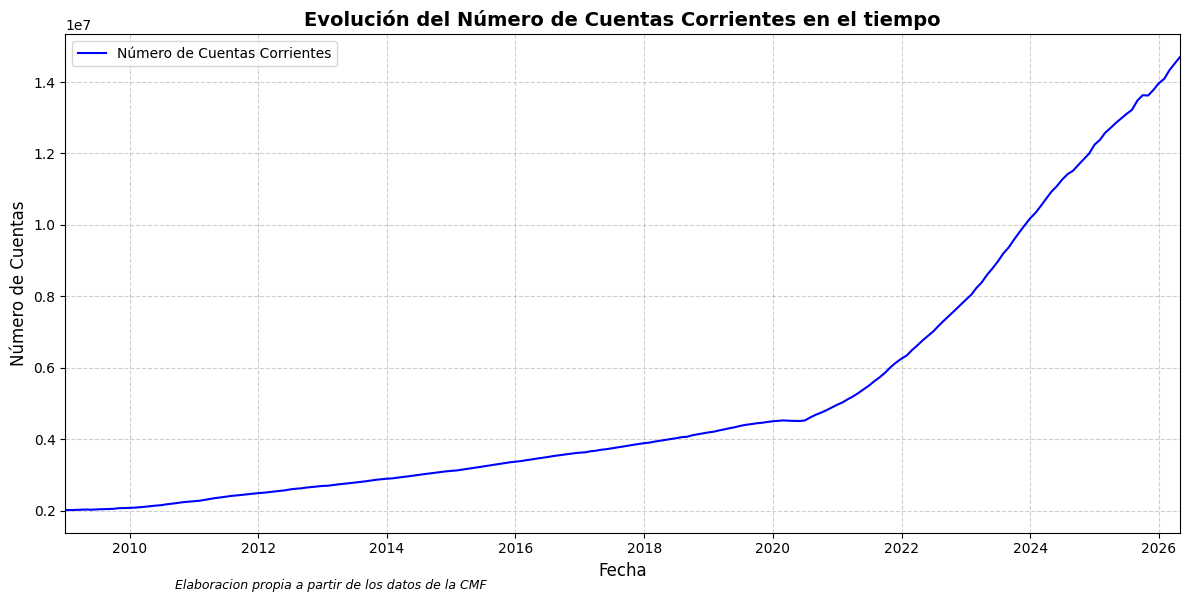

In [38]:
plt.figure(figsize=(12, 6))

plt.plot(df[columna_fecha], df[columna_valor], color='b', label='Número de Cuentas Corrientes')

plt.title('Evolución del Número de Cuentas Corrientes en el tiempo', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de Cuentas', fontsize=12)

plt.xlim(pd.Timestamp('2009-01-01'), df[columna_fecha].max())

plt.legend(loc='upper left')
plt.figtext(0.15, 0.01, 'Elaboracion propia a partir de los datos de la CMF', fontsize=9, fontstyle='italic')

plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# **7. Interpretación**

1. ¿Cuál es la tendencia general de la serie?

La serie muestra una tendencia creciente a lo largo de los años, desde el 1 de enero del 2009 hasta el 1 de mayo del 2026


2. ¿Se observan aumentos o disminuciones importantes?

Al ver el grafico pude observar que existen aumentos importantes despues del 2020, donde la cantidad de cuentas corrientes empieza a acelerar


3. ¿Existen períodos con valores especialmente altos o bajos?

 Los valores especialmente bajos se concentran al inicio de la serie (con un mínimo de aproximadamente 2,01 millones en febrero de 2009), mientras que los valores más altos se alcanzan hacia el final del periodo evaluado, superando los 14,7 millones de cuentas en mayo de 2026

 4.¿Se aprecia algún patrón, fluctuación o cambio relevante?

 Se aprecia un patron de crecimiento expansivo, reflejando un mayor acceso de la poblacion al sistema bancario